# Machine Learning & AI – Week 3

## Iris Flower Clustering Project

### Objective
The objective of this project is to apply unsupervised machine learning techniques to the Iris dataset using K-Means Clustering and Principal Component Analysis (PCA).

### Topics Covered
- K-Means Clustering
- Principal Component Analysis (PCA)
- Elbow Method
- Feature Scaling
- Model Saving and Loading using Joblib

### Dataset
Iris Flower Dataset (Scikit-learn)

### Libraries Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

## Task 1: Loading and Exploring the Iris Dataset

The Iris dataset contains 150 flower samples with four numerical features: sepal length, sepal width, petal length, and petal width.

The dataset is loaded using Scikit-learn and converted into a Pandas DataFrame for analysis.

In [3]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['Species'] = iris.target

display(df.head())

print("Dataset Shape:", df.shape)
print(df.info())
display(df.describe())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dataset Shape: (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Task 2: Feature Scaling

Feature scaling is performed using StandardScaler to bring all numerical features to a similar scale.

This step is important because K-Means uses distance calculations to form clusters. Features with larger values could otherwise dominate the clustering process.

In [4]:
X = df[iris.feature_names]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed!")
print(X_scaled[:5])

Feature Scaling Completed!
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


## Task 3: Elbow Method

The Elbow Method is used to determine the optimal number of clusters.

It calculates the Within-Cluster Sum of Squares (WCSS) for different values of K. The elbow point helps identify a suitable number of clusters.

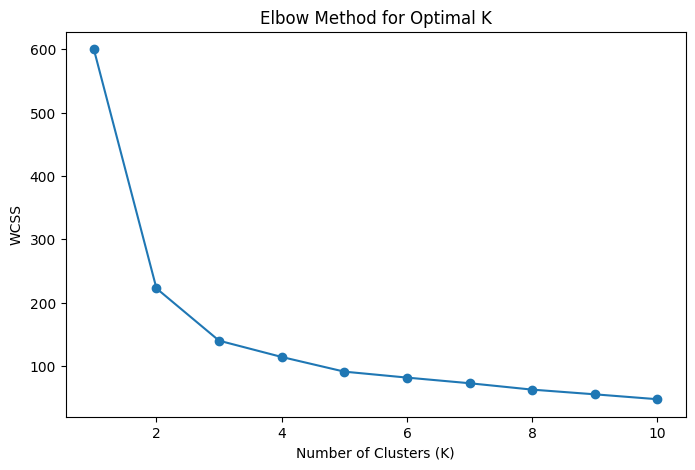

In [5]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.show()

## Assignment 1: K-Means Clustering on Iris Dataset

K-Means is an unsupervised machine learning algorithm that groups similar data points into clusters.

In this project, K-Means is applied with three clusters to group Iris flower samples based on their features.

In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Predicted_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")

display(df.head(10))

print("\nCluster Counts:")
print(df['Predicted_Cluster'].value_counts())

K-Means Clustering Completed!


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Predicted_Cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1
5,5.4,3.9,1.7,0.4,0,1
6,4.6,3.4,1.4,0.3,0,1
7,5.0,3.4,1.5,0.2,0,1
8,4.4,2.9,1.4,0.2,0,1
9,4.9,3.1,1.5,0.1,0,1



Cluster Counts:
Predicted_Cluster
0    53
1    50
2    47
Name: count, dtype: int64


## Assignment 2: Principal Component Analysis (PCA)

PCA is a dimensionality reduction technique used to reduce the number of features while retaining as much important information as possible.

In this project, the original four Iris features are reduced to two principal components to make visualization easier.

In [7]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['Principal Component 1', 'Principal Component 2']
)

pca_df['Cluster'] = df['Predicted_Cluster']

display(pca_df.head())

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

,Principal Component 1,Principal Component 2,Cluster
0,-2.264703,0.480027,1
1,-2.080961,-0.674134,1
2,-2.364229,-0.341908,1
3,-2.299384,-0.597395,1
4,-2.389842,0.646835,1


Explained Variance Ratio: [0.72962445 0.22850762]
Total Explained Variance: 0.9581320720000165


## Mini Project 3: Iris Flower Clustering Project

### Objective
To group Iris flowers into three clusters using K-Means and visualize the results using PCA.

### Cluster Visualization
The two principal components are used to create a two-dimensional scatter plot showing the three predicted clusters.

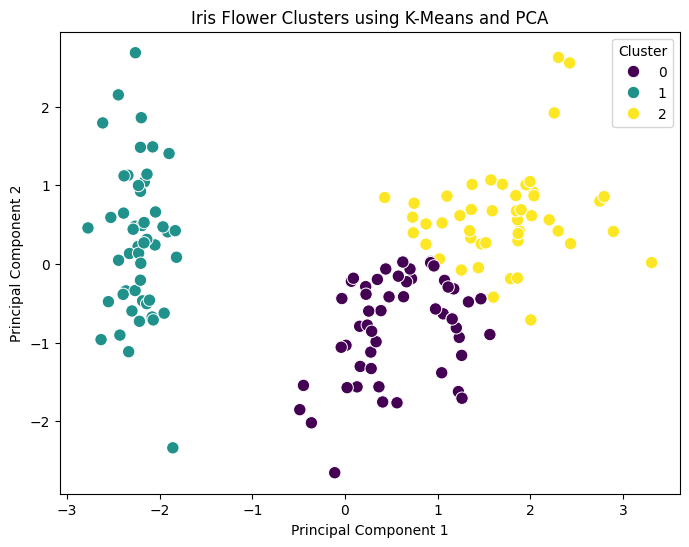

In [8]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.title("Iris Flower Clusters using K-Means and PCA")
plt.show()

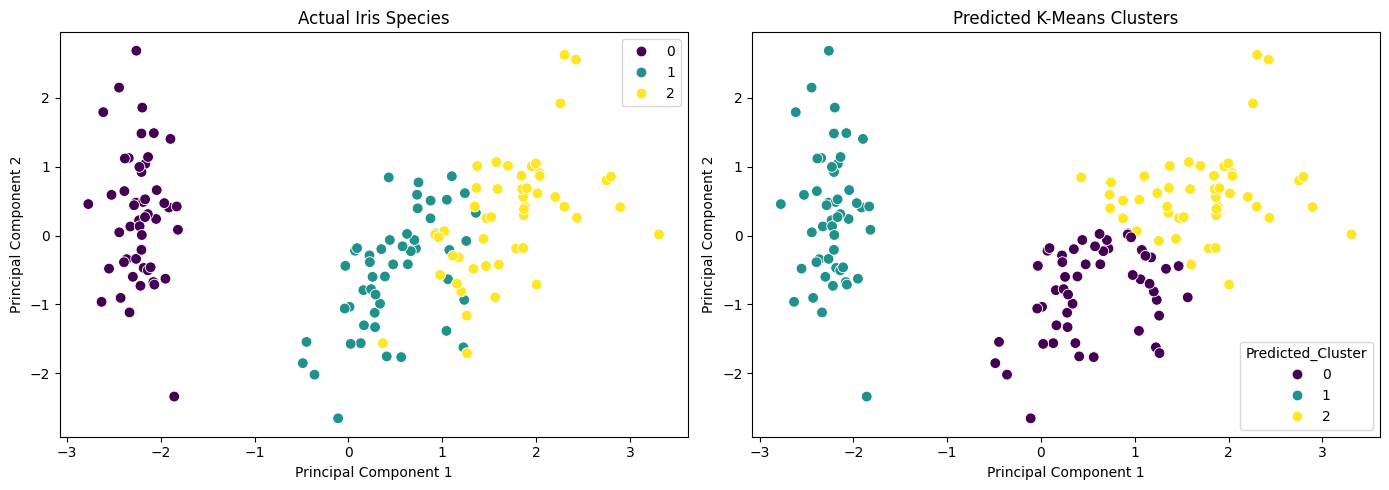

In [9]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=iris.target,
    palette='viridis',
    s=60
)

plt.title("Actual Iris Species")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.subplot(1, 2, 2)

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Predicted_Cluster'],
    palette='viridis',
    s=60
)

plt.title("Predicted K-Means Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [10]:
ari = adjusted_rand_score(
    iris.target,
    df['Predicted_Cluster']
)

print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.6201351808870379


## Model Saving and Loading

Model persistence allows us to save trained machine learning models and reuse them later without training them again.

In this task, Joblib and Pickle are used to save and load the trained K-Means model.

In [11]:
# Save models
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(pca, 'pca_model.pkl')

print("Models saved successfully!")

# Load model
loaded_model = joblib.load('kmeans_model.pkl')

# Test loaded model
new_predictions = loaded_model.predict(X_scaled)

print("Loaded Model Predictions:")
print(new_predictions[:10])

Models saved successfully!
Loaded Model Predictions:
[1 1 1 1 1 1 1 1 1 1]


In [12]:
import pickle

# Save model
with open('kmeans_pickle.pkl', 'wb') as file:
    pickle.dump(kmeans, file)

# Load model
with open('kmeans_pickle.pkl', 'rb') as file:
    loaded_pickle_model = pickle.load(file)

print("Pickle Model Loaded Successfully!")

print(loaded_pickle_model.predict(X_scaled[:5]))

Pickle Model Loaded Successfully!
[1 1 1 1 1]


## Conclusion

In this project, unsupervised machine learning techniques were successfully implemented using the Iris dataset.

- K-Means Clustering was applied with three clusters.
- The Elbow Method was used to study the optimal number of clusters.
- StandardScaler was used for feature scaling.
- PCA reduced the original four features into two principal components.
- Predicted clusters were compared with actual Iris species.
- Adjusted Rand Index was used to evaluate clustering similarity.
- The trained model was saved and loaded using Joblib and Pickle.

This project provided practical knowledge of unsupervised learning, dimensionality reduction, clustering, visualization, and model persistence.